# MahaMonsoon-X — Three-Model Comparison
## Multiple Linear Regression • AIMRI • ConvLSTM

This notebook loads the existing saved artifacts and processed ERA5 CSV, samples **50 unique years** (25 from 1975–1999 and 25 from 2000–2026), produces predictions, evaluates all models on the same common observations, and saves CSV metrics, graphs, and a ranking.

**Important validity note:** these years may overlap the models' training periods. The notebook audits overlap and labels the result accordingly. A ranking on training years is descriptive, not an unbiased test. For a rigorous test, all three models must be retrained with these years excluded.

Regression has no conventional classification accuracy. We report MAE, RMSE, \(R^2\), range-normalized error percentage, and a range-normalized score (explicitly **not accuracy**):

\[
E_{\mathrm{range}}=100\frac{\mathrm{MAE}}{\max(y)-\min(y)},\qquad
S_{\mathrm{range}}=100-E_{\mathrm{range}}.
\]

The primary ranking is ascending MAE, then RMSE.

## 1. Paths and imports

Run from the project root. All comparison outputs go to `artifacts/model_comparison/`.

In [9]:
from pathlib import Path
import json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, torch
from torch import nn
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEED = 42
rng = np.random.default_rng(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path.cwd()
CSV = ROOT / "data/processed/era5_processed.csv"
LR_PATH = ROOT / "artifacts/linear_regression/models/multiple_linear_regression_pipeline.joblib"
LR_META = ROOT / "artifacts/linear_regression/models/model_metadata.json"
AIMRI_CFG = ROOT / "artifacts/aimri/models/aimri_config.json"
AIMRI_META = ROOT / "artifacts/aimri/models/model_metadata.json"
CL_PATH = ROOT / "artifacts/convlstm/models/mahamonsoon_convlstm.pt"
CL_SCALERS = ROOT / "artifacts/convlstm/models/preprocessing_scalers.joblib"
CL_META = ROOT / "artifacts/convlstm/models/model_metadata.json"
OUT = ROOT / "artifacts/model_comparison"
RES, FIG = OUT / "results", OUT / "figures"
for d in (RES, FIG): d.mkdir(parents=True, exist_ok=True)
needed = [CSV, LR_PATH, LR_META, AIMRI_CFG, AIMRI_META, CL_PATH, CL_SCALERS, CL_META]
missing = [str(p) for p in needed if not p.exists()]
if missing:
    raise FileNotFoundError("Run the three model notebooks first. Missing:\n" + "\n".join(missing))
print("Device:", DEVICE, "| CSV:", CSV.resolve())


Device: cpu | CSV: D:\Projects\MahaMonsoon-X-Advanced-Progressive-Spatiotemporal-Rainfall-Intelligence\data\processed\era5_processed.csv


## 2. Load processed data and saved artifacts

The dataset uses `timestamp`, `latitude`, `longitude`, and `tp`. No new preprocessing or imputation is performed here.

In [10]:
data = pd.read_csv(CSV)
data.columns = data.columns.astype(str).str.strip()
data["timestamp"] = pd.to_datetime(data["timestamp"], errors="raise")
data["year"] = data.timestamp.dt.year.astype(int)
data["month"] = data.timestamp.dt.month.astype(int)
for col in ["latitude", "longitude", "tp"]:
    data[col] = pd.to_numeric(data[col], errors="raise")
data = data.replace([np.inf, -np.inf], np.nan)

lr_meta = json.loads(LR_META.read_text(encoding="utf-8"))
aimri_cfg = json.loads(AIMRI_CFG.read_text(encoding="utf-8"))
aimri_meta = json.loads(AIMRI_META.read_text(encoding="utf-8"))
cl_meta = json.loads(CL_META.read_text(encoding="utf-8"))
cl_scalers = joblib.load(CL_SCALERS)
lr_model = joblib.load(LR_PATH)
print("Data rows:", len(data), "| year range:", data.year.min(), "–", data.year.max())
print("LR feature count:", len(lr_meta["feature_columns"]))
print("AIMRI config:", aimri_cfg)


Data rows: 3565782 | year range: 1940 – 2026
LR feature count: 22
AIMRI config: {'lookback_years': 10, 'recency_factor': 1.0, 'min_history': 3}


## 3. Select 50 reproducible, unique years

There are 25 years in 1975–1999 and 27 years in 2000–2026. We sample 25 from each band for 50 unique years total. If any sampled year is absent from the CSV, the notebook stops rather than silently changing the requested sample.

In [11]:
historical_pool = np.arange(1975, 2000)
recent_pool = np.arange(2000, 2027)
selected_years = np.sort(np.r_[
    rng.choice(historical_pool, size=25, replace=False),
    rng.choice(recent_pool, size=25, replace=False)
]).astype(int)
absent = sorted(set(selected_years) - set(data.year.unique()))
if absent:
    raise ValueError(f"Selected years missing from CSV: {absent}")
assert len(selected_years) == len(np.unique(selected_years)) == 50
year_table = pd.DataFrame({"year": selected_years})
year_table["period"] = np.where(year_table.year < 2000, "1975–1999", "2000–2026")
year_table.to_csv(RES / "selected_50_test_years.csv", index=False)
display(year_table)


,year,period
0,1975,1975–1999
1,1976,1975–1999
2,1977,1975–1999
3,1978,1975–1999
4,1979,1975–1999
5,1980,1975–1999
6,1981,1975–1999
7,1982,1975–1999
8,1983,1975–1999
9,1984,1975–1999


## 4. Audit overlap with saved training periods

The saved metadata records training year ranges. If any sampled year overlaps a model's training range, its prediction for that year is not an independent test prediction. The comparison remains useful as a reproducibility check, but must not be presented as an unbiased ranking.

In [12]:
def year_range(meta, key):
    v = meta.get(key)
    return set(range(int(v[0]), int(v[1])+1)) if isinstance(v, list) and len(v)==2 else set()
audit = []
for name, meta in [("Multiple Linear Regression", lr_meta), ("AIMRI", aimri_meta), ("ConvLSTM", cl_meta)]:
    trained = year_range(meta, "train_years")
    overlap = sorted(set(selected_years) & trained)
    audit.append({"model": name, "training_range_known": bool(trained),
                  "overlap_count": len(overlap), "overlap_years": ",".join(map(str, overlap)),
                  "clean_holdout": bool(trained) and not overlap})
audit_df = pd.DataFrame(audit)
display(audit_df)
audit_df.to_csv(RES / "training_overlap_audit.csv", index=False)
if (audit_df.overlap_count > 0).any():
    warnings.warn("Selected years overlap at least one training range: ranking is descriptive, not an unbiased test.")


,model,training_range_known,overlap_count,overlap_years,clean_holdout
0,Multiple Linear Regression,True,25,"1975,1976,1977,1978,1979,1980,1981,1982,1983,1...",False
1,AIMRI,True,25,"1975,1976,1977,1978,1979,1980,1981,1982,1983,1...",False
2,ConvLSTM,True,25,"1975,1976,1977,1978,1979,1980,1981,1982,1983,1...",False


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16152\13599101.py:15: UserWarning: Selected years overlap at least one training range: ranking is descriptive, not an unbiased test.
  warnings.warn("Selected years overlap at least one training range: ranking is descriptive, not an unbiased test.")


## 5. Multiple Linear Regression predictions

Reconstruct the exact lag and calendar feature schema saved with the Ridge pipeline. Current-month weather predictors are used because that is how the LR notebook was trained; interpret this as a retrospective estimate unless those predictors are available at forecast issue time.

In [13]:
lr_data = data.sort_values(["latitude", "longitude", "timestamp"]).copy()
grp = lr_data.groupby(["latitude", "longitude"], sort=False)["tp"]
for lag in [1, 2, 3, 6, 12]:
    lr_data[f"tp_lag_{lag}"] = grp.shift(lag)
lr_data["month_sin"] = np.sin(2*np.pi*lr_data.month/12)
lr_data["month_cos"] = np.cos(2*np.pi*lr_data.month/12)
lr_features = lr_meta["feature_columns"]
missing_features = [c for c in lr_features if c not in lr_data.columns]
if missing_features: raise ValueError(f"Cannot reconstruct LR feature schema: {missing_features}")
lr_eval = lr_data[lr_data.year.isin(selected_years)].dropna(
    subset=["tp"] + [c for c in lr_features if c.startswith("tp_lag_")]
).copy()
lr_eval["lr_prediction"] = lr_model.predict(lr_eval[lr_features])
lr_eval = lr_eval[["year","month","latitude","longitude","tp","lr_prediction"]].rename(columns={"tp":"actual"})
print("LR rows predicted:", len(lr_eval))


LR rows predicted: 2049300


## 6. AIMRI predictions

AIMRI averages same-month rainfall at the same grid cell over the previous \(K\) years. A recency factor \(\rho\) gives lag \(k\) weight \(w_k=\rho^{k-1}\), with lag 1 the most recent year. Only valid history contributes to the weighted denominator.

In [14]:

K = int(aimri_cfg["lookback_years"])
rho = float(aimri_cfg["recency_factor"])
min_history = int(aimri_cfg.get("min_history", 3))

key_cols = ["year", "month", "latitude", "longitude"]

# Keep one rainfall value per year-month-grid cell.
# Duplicate records are combined using their mean.
aimri_data = (
    data[key_cols + ["tp"]]
    .groupby(key_cols, as_index=False, sort=False)
    .agg(tp=("tp", "mean"))
)

base = aimri_data.rename(columns={"tp": "actual"}).copy()
history = aimri_data.rename(columns={"tp": "rain"}).copy()

# Vectorized historical joins: lag 1 means the previous year.
for lag in range(1, K + 1):
    shifted = history.copy()
    shifted["year"] = shifted["year"] + lag
    shifted = shifted.rename(columns={"rain": f"lag_{lag}"})

    base = base.merge(
        shifted[key_cols + [f"lag_{lag}"]],
        on=key_cols,
        how="left",
        validate="one_to_one"
    )

def aimri_predict(frame):
    lag_cols = [f"lag_{k}" for k in range(1, K + 1)]
    vals = frame[lag_cols].to_numpy(dtype=float)

    # Lag 1 is most recent; older years receive lower weights
    # when rho is less than 1.
    weights = np.array(
        [rho ** (k - 1) for k in range(1, K + 1)],
        dtype=float
    )

    valid = np.isfinite(vals)
    numerator = np.nansum(vals * weights[None, :], axis=1)
    denominator = (valid * weights[None, :]).sum(axis=1)
    history_count = valid.sum(axis=1)

    return np.divide(
        numerator,
        denominator,
        out=np.full(len(frame), np.nan, dtype=float),
        where=(denominator > 0) & (history_count >= min_history)
    )

aimri_eval = base[base["year"].isin(selected_years)].copy()

aimri_eval["aimri_prediction"] = aimri_predict(aimri_eval)

aimri_eval = aimri_eval[
    key_cols + ["actual", "aimri_prediction"]
]

print("Unique grid-month records:", len(aimri_data))
print("AIMRI evaluation rows:", len(aimri_eval))
print(
    "AIMRI rows with predictions:",
    int(aimri_eval["aimri_prediction"].notna().sum())
)
print(
    "Rows without sufficient historical data:",
    int(aimri_eval["aimri_prediction"].isna().sum())
)

display(aimri_eval.head())


Unique grid-month records: 1782891
AIMRI evaluation rows: 1024650
AIMRI rows with predictions: 1024650
Rows without sufficient historical data: 0


,year,month,latitude,longitude,actual,aimri_prediction
717255,1975,1,14.75,65.25,-0.393566,-0.385463
717256,1975,1,14.75,65.50,-0.394059,-0.387227
717257,1975,1,14.75,65.75,-0.394552,-0.387436
717258,1975,1,14.75,66.00,-0.396525,-0.387412
717259,1975,1,14.75,66.25,-0.397758,-0.386906


## 7. ConvLSTM predictions

The saved ConvLSTM model expects the exact grid shape, feature order, and channel layout used during training. This cell rebuilds the monthly cube, applies the saved training scalers, appends missingness channels and historical rainfall, and predicts the configured target months.

In [15]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hidden, kernel):
        super().__init__(); self.hidden=hidden
        self.gates=nn.Conv2d(in_ch+hidden, 4*hidden, kernel, padding=kernel//2)
    def forward(self,x,state):
        h,c=state; i,f,g,o=torch.chunk(self.gates(torch.cat([x,h],1)),4,1)
        i,f,o=torch.sigmoid(i),torch.sigmoid(f),torch.sigmoid(o); g=torch.tanh(g)
        c=f*c+i*g; h=o*torch.tanh(c); return h,c
    def init_state(self,b,h,w,device):
        shape=(b,self.hidden,h,w); return torch.zeros(shape,device=device),torch.zeros(shape,device=device)
class ConvLSTMForecaster(nn.Module):
    def __init__(self, in_ch, hidden, kernel):
        super().__init__(); self.hidden=hidden
        self.cell=ConvLSTMCell(in_ch,hidden,kernel); self.head=nn.Conv2d(hidden,1,1)
    def forward(self,x):
        b,t,_,h,w=x.shape; state=self.cell.init_state(b,h,w,x.device)
        for k in range(t): state=self.cell(x[:,k],state)
        return self.head(state[0])

checkpoint = torch.load(CL_PATH, map_location=DEVICE, weights_only=True)
conv_model = ConvLSTMForecaster(checkpoint["input_channels"],checkpoint["hidden_channels"],checkpoint["kernel_size"]).to(DEVICE)
conv_model.load_state_dict(checkpoint["state_dict"]); conv_model.eval()
conv_features = cl_meta["feature_columns"]
lats, lons = np.asarray(cl_meta["latitudes"],float), np.asarray(cl_meta["longitudes"],float)
H,W = map(int,cl_meta["grid_shape"]); seq_len=int(cl_meta["sequence_length"])
target_months=cl_meta.get("target_months",[6,7,8,9])
medians=np.asarray(cl_scalers["feature_medians"],float)
xs,ys=cl_scalers["x_scaler"],cl_scalers["y_scaler"]
if len(conv_features)!=len(medians) or (H,W)!=(len(lats),len(lons)):
    raise ValueError("ConvLSTM metadata, grid, or scaler schema mismatch.")

cd=data[data.latitude.isin(lats)&data.longitude.isin(lons)].copy()
agg={"tp":"mean", **{c:"mean" for c in conv_features if c in cd.columns}}
cd=cd.groupby(["year","month","latitude","longitude"],as_index=False).agg(agg)
start,end=int(cd.year.min()),int(cd.year.max())
timeline=pd.period_range(f"{start}-01",f"{end}-12",freq="M")
pmap={p:i for i,p in enumerate(timeline)}; latmap={v:i for i,v in enumerate(lats)}; lonmap={v:i for i,v in enumerate(lons)}
T,F=len(timeline),len(conv_features)
Xraw=np.full((T,H,W,F),np.nan,np.float32); Yraw=np.full((T,H,W),np.nan,np.float32)
cd["_period"]=pd.PeriodIndex(year=cd.year,month=cd.month,freq="M")
cd["_t"]=cd["_period"].map(pmap); cd["_i"]=cd.latitude.map(latmap); cd["_j"]=cd.longitude.map(lonmap)
cd=cd.dropna(subset=["_t","_i","_j"]); ti,ii,jj=(cd[c].to_numpy(int) for c in ["_t","_i","_j"])
for k,col in enumerate(conv_features):
    if col not in cd: raise ValueError(f"ConvLSTM input feature missing from CSV: {col}")
    Xraw[ti,ii,jj,k]=pd.to_numeric(cd[col],errors="coerce").to_numpy(np.float32)
Yraw[ti,ii,jj]=pd.to_numeric(cd.tp,errors="coerce").to_numpy(np.float32)
Xfill=np.where(np.isfinite(Xraw),Xraw,medians.reshape(1,1,1,-1))
Xscaled=xs.transform(Xfill.reshape(-1,F)).reshape(T,H,W,F).astype(np.float32)
Xmiss=(~np.isfinite(Xraw)).astype(np.float32)
Yscaled=np.full_like(Yraw,np.nan)
masky=np.isfinite(Yraw); Yscaled[masky]=ys.transform(Yraw[masky].reshape(-1,1)).ravel()
Xmodel=np.concatenate([Xscaled,Xmiss,np.nan_to_num(Yscaled,nan=0)[...,None],(~np.isfinite(Yscaled))[...,None].astype(np.float32)],axis=-1)
if Xmodel.shape[-1]!=checkpoint["input_channels"]:
    raise ValueError(f"ConvLSTM expects {checkpoint['input_channels']} channels, rebuilt {Xmodel.shape[-1]}.")
ty=np.array([p.year for p in timeline]); tm=np.array([p.month for p in timeline])
conv_rows=[]
with torch.no_grad():
    for t in range(seq_len,T):
        yr,mo=int(ty[t]),int(tm[t])
        if yr not in set(selected_years) or mo not in target_months: continue
        mask=np.isfinite(Yraw[t])
        if not mask.any(): continue
        x=np.transpose(Xmodel[t-seq_len:t],(0,3,1,2))[None].copy()
        pred_s=conv_model(torch.from_numpy(x).float().to(DEVICE)).cpu().numpy()[0,0]
        pred=ys.inverse_transform(pred_s.reshape(-1,1)).reshape(H,W)
        for i,j in zip(*np.where(mask)):
            conv_rows.append({"year":yr,"month":mo,"latitude":float(lats[i]),"longitude":float(lons[j]),"convlstm_prediction":float(pred[i,j])})
conv_eval=pd.DataFrame(conv_rows)
if conv_eval.empty: raise ValueError("ConvLSTM produced no predictions for selected years.")
print("ConvLSTM rows predicted:",len(conv_eval))


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_16152\3829398032.py:40: FutureWarning: Constructing PeriodIndex from fields is deprecated. Use PeriodIndex.from_fields instead.
  cd["_period"]=pd.PeriodIndex(year=cd.year,month=cd.month,freq="M")


ConvLSTM rows predicted: 455400


## 8. Join on identical year-month-grid observations

The final comparison uses the intersection where all three models have a finite prediction and the actual target is present. This prevents models from being compared on different/easier subsets. ConvLSTM is evaluated only on its configured target months.

In [16]:
keys=["year","month","latitude","longitude"]
actual=data[data.year.isin(selected_years)][keys+["tp"]].rename(columns={"tp":"actual"}).drop_duplicates(keys)
joined=actual.merge(lr_eval[keys+["lr_prediction"]],on=keys,how="inner")
joined=joined.merge(aimri_eval[keys+["aimri_prediction"]],on=keys,how="inner")
joined=joined.merge(conv_eval[keys+["convlstm_prediction"]],on=keys,how="inner")
joined=joined.replace([np.inf,-np.inf],np.nan).dropna(subset=["actual","lr_prediction","aimri_prediction","convlstm_prediction"])
if joined.empty: raise ValueError("No common observations. Check grid, months, and artifact versions.")
joined.to_csv(RES/"all_models_common_predictions.csv",index=False)
print("Common rows:",len(joined)," | common years:",joined.year.nunique())
display(joined.head())


Common rows: 910800  | common years: 50


,year,month,latitude,longitude,actual,lr_prediction,aimri_prediction,convlstm_prediction
0,1975,6,14.75,65.25,-0.326109,-0.353808,0.044029,0.132628
1,1975,6,14.75,65.25,-0.326109,-0.121251,0.044029,0.132628
2,1975,6,14.75,65.50,-0.326109,-0.352157,0.052489,0.429335
3,1975,6,14.75,65.50,-0.326109,-0.043853,0.052489,0.429335
4,1975,6,14.75,65.75,-0.326109,-0.352338,0.083590,0.441505


## 9. Metrics and ranking

All metrics use the exact same rows. Primary ranking is lowest MAE, with RMSE as tie-breaker. The percentage columns normalize MAE by the observed range and must not be called conventional accuracy.

In [17]:
target_range=float(joined.actual.max()-joined.actual.min())
rows=[]
for name,col in [("Multiple Linear Regression","lr_prediction"),("AIMRI","aimri_prediction"),("ConvLSTM","convlstm_prediction")]:
    yt=joined.actual.to_numpy(float); yp=joined[col].to_numpy(float)
    mae=float(mean_absolute_error(yt,yp)); rmse=float(np.sqrt(mean_squared_error(yt,yp)))
    errpct=100*mae/target_range if target_range>0 else np.nan
    rows.append({"model":name,"MAE":mae,"RMSE":rmse,"R2":float(r2_score(yt,yp)),
                 "Error percentage (range-normalized)":errpct,
                 "Normalized score (%) — not accuracy":100-errpct if np.isfinite(errpct) else np.nan,
                 "evaluated_rows":len(yt),"evaluated_years":int(joined.year.nunique())})
metrics=pd.DataFrame(rows).sort_values(["MAE","RMSE"]).reset_index(drop=True)
metrics.insert(0,"rank_by_MAE_then_RMSE",np.arange(1,len(metrics)+1))
display(metrics.round(5))
metrics.to_csv(RES/"model_comparison_metrics.csv",index=False)
metrics[["rank_by_MAE_then_RMSE","model","MAE","RMSE","R2"]].to_csv(RES/"model_ranking.csv",index=False)


,rank_by_MAE_then_RMSE,model,MAE,RMSE,R2,Error percentage (range-normalized),Normalized score (%) — not accuracy,evaluated_rows,evaluated_years
0,1,AIMRI,0.72670,0.92279,-3.070485e+31,NaN,NaN,910800,50
1,2,ConvLSTM,0.74881,0.91711,-3.032775e+31,NaN,NaN,910800,50
2,3,Multiple Linear Regression,0.77389,1.43088,-7.382503e+31,NaN,NaN,910800,50


## 10. Comparison plots

MAE, RMSE, and normalized error should be minimized; \(R^2\) should generally be maximized. The normalized score is not classification accuracy.

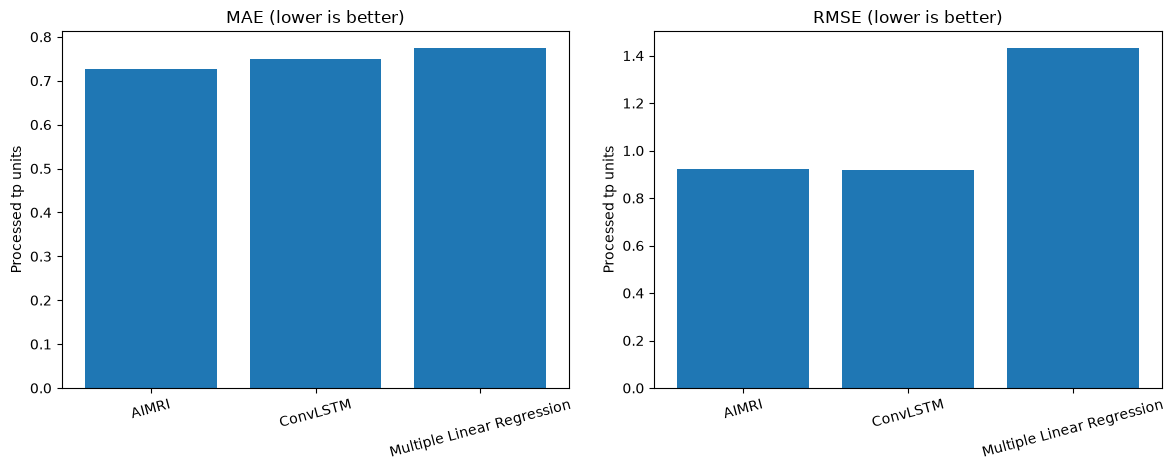

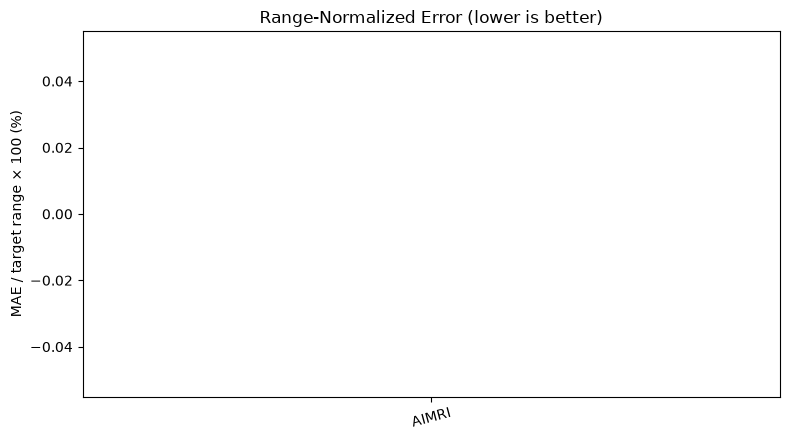

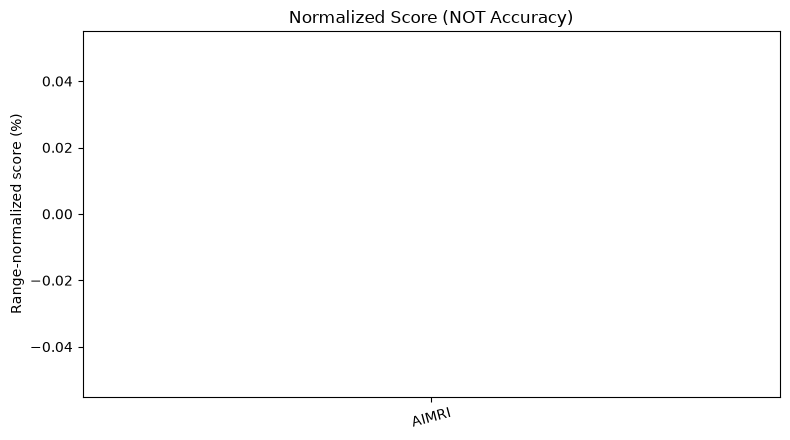

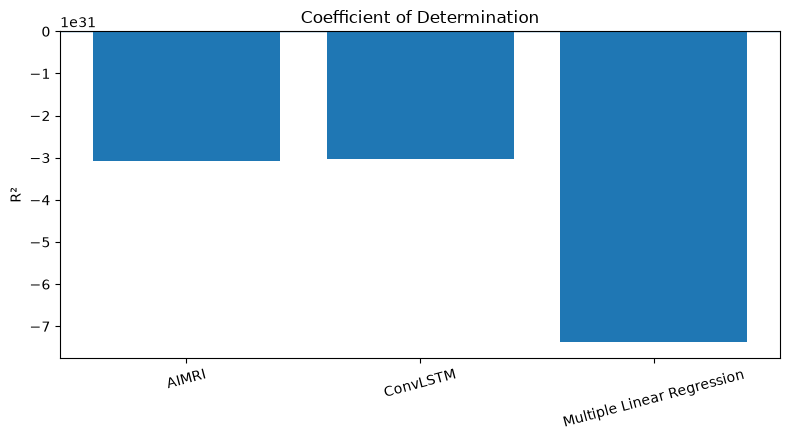

In [18]:
fig,ax=plt.subplots(1,2,figsize=(12,4.8))
ax[0].bar(metrics.model,metrics.MAE); ax[0].set_title("MAE (lower is better)"); ax[0].set_ylabel("Processed tp units"); ax[0].tick_params(axis="x",rotation=15)
ax[1].bar(metrics.model,metrics.RMSE); ax[1].set_title("RMSE (lower is better)"); ax[1].set_ylabel("Processed tp units"); ax[1].tick_params(axis="x",rotation=15)
fig.tight_layout(); fig.savefig(FIG/"mae_rmse_comparison.png",dpi=160,bbox_inches="tight"); plt.show()

plt.figure(figsize=(8,4.5)); plt.bar(metrics.model,metrics["Error percentage (range-normalized)"])
plt.ylabel("MAE / target range × 100 (%)"); plt.title("Range-Normalized Error (lower is better)"); plt.xticks(rotation=15); plt.tight_layout()
plt.savefig(FIG/"error_percentage_comparison.png",dpi=160,bbox_inches="tight"); plt.show()

plt.figure(figsize=(8,4.5)); plt.bar(metrics.model,metrics["Normalized score (%) — not accuracy"])
plt.ylabel("Range-normalized score (%)"); plt.title("Normalized Score (NOT Accuracy)"); plt.xticks(rotation=15); plt.tight_layout()
plt.savefig(FIG/"normalized_score_comparison.png",dpi=160,bbox_inches="tight"); plt.show()

plt.figure(figsize=(8,4.5)); plt.bar(metrics.model,metrics.R2); plt.axhline(0,linewidth=1)
plt.ylabel("R²"); plt.title("Coefficient of Determination"); plt.xticks(rotation=15); plt.tight_layout()
plt.savefig(FIG/"r2_comparison.png",dpi=160,bbox_inches="tight"); plt.show()


## 11. Save report and inspect outputs

The report records the selected years, training-overlap audit, common row count, metrics, and ranking. Always inspect the overlap audit before describing the ranking as generalization performance.

In [19]:
report={
 "project":"MahaMonsoon-X",
 "comparison_type":"existing saved models on sampled historical years",
 "seed":SEED,
 "selected_years":selected_years.tolist(),
 "selected_year_count":len(selected_years),
 "common_rows":len(joined),
 "common_years":int(joined.year.nunique()),
 "training_overlap_audit":audit,
 "ranking_rule":"ascending MAE then ascending RMSE",
 "accuracy_note":"Regression has no conventional classification accuracy; normalized score is not accuracy.",
 "metrics":metrics.to_dict(orient="records")
}
(RES/"comparison_report.json").write_text(json.dumps(report,indent=2),encoding="utf-8")
print("Results:",RES.resolve())
for p in sorted(RES.glob("*")): print(p.name, f"{p.stat().st_size/1024:.1f} KB")
print("Figures:",[p.name for p in sorted(FIG.glob("*"))])


Results: D:\Projects\MahaMonsoon-X-Advanced-Progressive-Spatiotemporal-Rainfall-Intelligence\artifacts\model_comparison\results
all_models_common_predictions.csv 77656.9 KB
comparison_report.json 2.9 KB
model_comparison_metrics.csv 0.4 KB
model_ranking.csv 0.3 KB
selected_50_test_years.csv 0.9 KB
training_overlap_audit.csv 0.5 KB
Figures: ['error_percentage_comparison.png', 'mae_rmse_comparison.png', 'normalized_score_comparison.png', 'r2_comparison.png']


## 12. Interpretation checklist

1. If sampled years overlap a model's training years, ranking is descriptive and potentially in-sample.
2. All metrics use identical common rows, not each model's full individual output.
3. Metrics are in the processed CSV target scale. Verify upstream `tp` standardization and ERA5 unit conversion.
4. LR uses current-month weather predictors as in its original training notebook; this may be retrospective rather than a forecast available in advance.
5. AIMRI uses prior same-month observations. ConvLSTM uses its saved monthly sequence and grid schema.
6. For a scientifically rigorous final ranking, retrain all three models with the same 50 years excluded from training, and preserve an identical target-month/availability protocol.